# ACTIVIDAD 3 – SIMULACIÓN
## Problema bancario: sistema de atención de cajeros

**Asignatura:** Simulación  
**Herramienta:** Google Colab y Python  
**Objetivo:** Simular la atención de usuarios en un banco con tres cajeros independientes, considerando retiros y pagos/consignaciones, para analizar tiempos de servicio, espera y desempeño.

- **Duración de cada jornada:** 480 minutos (8 horas).
- **Réplicas independientes:** mínimo 10.
- **Modelo de atención:** tres colas independientes (una por cajero).

> **Supuesto de modelado que debe declararse en el informe:** los usuarios llegan a un flujo común, se asigna aleatoriamente cada usuario a uno de los cajeros y espera en la cola de ese cajero. Los tiempos entre llegadas y de servicio se generan mediante distribuciones exponenciales usando las medias de la tabla del laboratorio. Esta interpretación permite representar colas separadas; si el profesor especificó una regla de asignación diferente, debe ajustarse.

In [ ]:
# BLOQUE 1. IMPORTACIÓN DE LIBRERÍAS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
# BLOQUE 2. CONFIGURACIÓN DEL PROBLEMA

TIEMPO_SIMULACION = 480
NUM_REPLICAS = 10
NUM_CAJEROS = 3

PROB_OPERACION = {
    "Retiro": 0.70,
    "Pago": 0.30
}

PROB_USUARIOS = {
    "Retiro": {
        "Rapido": 0.23,
        "Normal": 0.40,
        "Lento": 0.17,
        "Muy lento": 0.20
    },
    "Pago": {
        "Rapido": 0.10,
        "Normal": 0.20,
        "Lento": 0.30,
        "Muy lento": 0.40
    }
}

# Medias en minutos: tiempo de servicio y tiempo entre llegadas
DATOS_OPERACIONES = {
    "Retiro": {
        "Rapido": {"servicio": 1, "llegada": 1},
        "Normal": {"servicio": 2, "llegada": 2},
        "Lento": {"servicio": 3, "llegada": 3},
        "Muy lento": {"servicio": 4, "llegada": 3}
    },
    "Pago": {
        "Rapido": {"servicio": 3, "llegada": 1},
        "Normal": {"servicio": 3, "llegada": 2},
        "Lento": {"servicio": 5, "llegada": 3},
        "Muy lento": {"servicio": 7, "llegada": 4}
    }
}

# Validaciones para evitar errores silenciosos
assert np.isclose(sum(PROB_OPERACION.values()), 1.0)
for operacion, probabilidades in PROB_USUARIOS.items():
    assert np.isclose(sum(probabilidades.values()), 1.0), f"Probabilidades incorrectas: {operacion}"

tabla_parametros = pd.DataFrame([
    {
        "Operación": operacion,
        "Tipo de usuario": tipo,
        "Probabilidad del tipo": PROB_USUARIOS[operacion][tipo],
        "Media servicio (min)": valores["servicio"],
        "Media entre llegadas (min)": valores["llegada"]
    }
    for operacion, tipos in DATOS_OPERACIONES.items()
    for tipo, valores in tipos.items()
])

print("Configuración cargada y validada.")
print(f"Jornada: {TIEMPO_SIMULACION} minutos | Réplicas: {NUM_REPLICAS} | Cajeros: {NUM_CAJEROS}")
display(tabla_parametros)

Configuración cargada y validada.
Jornada: 480 minutos | Réplicas: 10 | Cajeros: 3


,Operación,Tipo de usuario,Probabilidad del tipo,Media servicio (min),Media entre llegadas (min)
0,Retiro,Rapido,0.23,1,1
1,Retiro,Normal,0.40,2,2
2,Retiro,Lento,0.17,3,3
3,Retiro,Muy lento,0.20,4,3
4,Pago,Rapido,0.10,3,1
5,Pago,Normal,0.20,3,2
6,Pago,Lento,0.30,5,3
7,Pago,Muy lento,0.40,7,4


In [ ]:
# BLOQUE 3. MOTOR DE SIMULACIÓN CON TRES COLAS INDEPENDIENTES

def simular_banco(semilla, tiempo_simulacion=TIEMPO_SIMULACION, cajeros=NUM_CAJEROS):
    """Simula una jornada. Cada cajero tiene su propia cola FIFO.

    Los usuarios llegan a un flujo común y se asignan aleatoriamente
    a uno de los cajeros. Los usuarios que llegan antes del cierre
    se registran aunque terminen su servicio después de los 480 minutos.
    """
    if cajeros < 1:
        raise ValueError("Debe existir al menos un cajero.")

    rng = np.random.default_rng(semilla)
    disponibilidad = np.zeros(cajeros, dtype=float)
    registros = []
    tiempo_llegada = 0.0

    operaciones = list(PROB_OPERACION.keys())
    probabilidades_operacion = list(PROB_OPERACION.values())

    while True:
        # Seleccionar la operación y el tipo del siguiente usuario
        operacion = rng.choice(operaciones, p=probabilidades_operacion)
        tipos = list(PROB_USUARIOS[operacion].keys())
        probabilidades_tipo = list(PROB_USUARIOS[operacion].values())
        tipo = rng.choice(tipos, p=probabilidades_tipo)

        parametros = DATOS_OPERACIONES[operacion][tipo]

        # La media de la exponencial es el valor de la tabla
        intervalo = rng.exponential(scale=parametros["llegada"])
        tiempo_llegada += intervalo

        if tiempo_llegada >= tiempo_simulacion:
            break

        # Asignación aleatoria: cada cajero conserva su propia cola
        cajero = int(rng.integers(0, cajeros))

        servicio = rng.exponential(scale=parametros["servicio"])
        inicio = max(tiempo_llegada, disponibilidad[cajero])
        final = inicio + servicio
        espera = inicio - tiempo_llegada

        disponibilidad[cajero] = final

        registros.append({
            "Cajero": cajero + 1,
            "Operacion": operacion,
            "Tipo": tipo,
            "Llegada": tiempo_llegada,
            "Inicio": inicio,
            "Servicio": servicio,
            "Espera": espera,
            "Tiempo_sistema": espera + servicio,
            "Final": final
        })

    columnas = [
        "Cajero", "Operacion", "Tipo", "Llegada", "Inicio",
        "Servicio", "Espera", "Tiempo_sistema", "Final"
    ]
    return pd.DataFrame(registros, columns=columnas)


# Prueba reproducible del motor
prueba = simular_banco(semilla=42)

print("Motor ejecutado correctamente.")
print("Usuarios que llegaron durante la jornada:", len(prueba))
print("\nUsuarios asignados a cada cajero:")
display(
    prueba["Cajero"].value_counts().sort_index()
    .rename_axis("Cajero").reset_index(name="Usuarios")
)
print("\nPrimeros 10 registros:")
display(prueba.head(10))

Motor ejecutado correctamente.
Usuarios que llegaron durante la jornada: 208

Usuarios asignados a cada cajero:


,Cajero,Usuarios
0,1,72
1,2,68
2,3,68



Primeros 10 registros:


,Cajero,Operacion,Tipo,Llegada,Inicio,Servicio,Espera,Tiempo_sistema,Final
0,1,Pago,Lento,7.154283,7.154283,0.432187,0.000000,0.432187,7.586470
1,3,Pago,Muy lento,19.651467,19.651467,0.555059,0.000000,0.555059,20.206526
2,3,Retiro,Normal,21.829514,21.829514,0.773790,0.000000,0.773790,22.603304
3,2,Retiro,Rapido,21.921091,21.921091,0.315179,0.000000,0.315179,22.236271
4,3,Pago,Muy lento,26.910635,26.910635,12.865792,0.000000,12.865792,39.776427
5,2,Pago,Muy lento,28.578982,28.578982,3.173238,0.000000,3.173238,31.752220
6,3,Retiro,Rapido,29.264302,39.776427,1.264207,10.512125,11.776331,41.040634
7,3,Retiro,Normal,30.186479,41.040634,1.283113,10.854155,12.137268,42.323747
8,2,Retiro,Normal,31.944308,31.944308,2.667405,0.000000,2.667405,34.611713
9,3,Pago,Muy lento,32.236422,42.323747,7.938473,10.087325,18.025798,50.262220


## Verificación del modelo

- Si las celdas se ejecutan en orden, no debe aparecer `NameError`.
- La cantidad de usuarios y los tiempos pueden cambiar al modificar la semilla.
- La misma semilla (`42`) reproduce los mismos resultados.
- `Espera` mide el tiempo antes de iniciar la atención; `Servicio` mide la atención; `Tiempo_sistema` es la suma de ambos.
- El conteo incluye usuarios que llegaron antes del minuto 480, incluso si su atención termina después del cierre.

In [ ]:

# BLOQUE 4: DIEZ RÉPLICAS INDEPENDIENTES

resultados_replicas = []
registros_completos = []

# Ejecutar las 10 jornadas
for replica in range(1, NUM_REPLICAS + 1):

    datos = simular_banco(
        semilla=1000 + replica,
        tiempo_simulacion=TIEMPO_SIMULACION,
        cajeros=NUM_CAJEROS
    )

    datos["Replica"] = replica
    registros_completos.append(datos)

    resultados_replicas.append({
        "Replica": replica,
        "Usuarios": len(datos),
        "Espera_promedio": datos["Espera"].mean(),
        "Servicio_promedio": datos["Servicio"].mean(),
        "Tiempo_sistema_promedio": datos["Tiempo_sistema"].mean(),
        "Espera_maxima": datos["Espera"].max()
    })

# Unir los registros de todas las réplicas
todos_los_usuarios = pd.concat(
    registros_completos,
    ignore_index=True
)

resumen_replicas = pd.DataFrame(resultados_replicas)

print("10 réplicas ejecutadas correctamente.")
display(resumen_replicas.round(3))


# ==========================================
# INTERVALOS DE CONFIANZA DEL 95 %
# ==========================================

def intervalo_confianza_media(valores, confianza=0.95):

    valores = pd.Series(valores).dropna()
    n = len(valores)
    media = valores.mean()

    if n < 2:
        return pd.Series({
            "Media": media,
            "Desv_estandar": np.nan,
            "IC_inferior": np.nan,
            "IC_superior": np.nan
        })

    desviacion = valores.std(ddof=1)

    error = (
        stats.t.ppf((1 + confianza) / 2, df=n - 1)
        * desviacion / np.sqrt(n)
    )

    return pd.Series({
        "Media": media,
        "Desv_estandar": desviacion,
        "IC_inferior": media - error,
        "IC_superior": media + error
    })


resumen_estadistico = pd.DataFrame({
    "Usuarios por réplica": intervalo_confianza_media(
        resumen_replicas["Usuarios"]
    ),
    "Espera promedio (min)": intervalo_confianza_media(
        resumen_replicas["Espera_promedio"]
    ),
    "Servicio promedio (min)": intervalo_confianza_media(
        resumen_replicas["Servicio_promedio"]
    ),
    "Tiempo en sistema (min)": intervalo_confianza_media(
        resumen_replicas["Tiempo_sistema_promedio"]
    )
}).T

print("\nRESUMEN ESTADÍSTICO E INTERVALOS DE CONFIANZA DEL 95 %")
display(resumen_estadistico.round(3))



# USUARIOS POR TIPO


print("\nCANTIDAD DE USUARIOS POR TIPO")

conteo_tipos = todos_los_usuarios["Tipo"].value_counts().reindex(
    ["Rapido", "Normal", "Lento", "Muy lento"],
    fill_value=0
)

display(
    conteo_tipos.rename_axis("Tipo de usuario")
    .reset_index(name="Cantidad")
)



# ESPERA PROMEDIO POR CAJERO


print("\nESPERA PROMEDIO POR CAJERO")

espera_cajero = (
    todos_los_usuarios.groupby("Cajero")["Espera"]
    .mean()
    .round(3)
)

display(
    espera_cajero.rename("Espera promedio (min)")
    .reset_index()
)

10 réplicas ejecutadas correctamente.


,Replica,Usuarios,Espera_promedio,Servicio_promedio,Tiempo_sistema_promedio,Espera_maxima
0,1,177,2.398,3.207,5.605,20.412
1,2,212,1.941,2.795,4.737,24.784
2,3,194,2.095,2.889,4.984,27.352
3,4,194,2.444,3.107,5.551,23.547
4,5,193,2.718,3.591,6.309,23.605
5,6,186,2.661,3.245,5.906,28.970
6,7,218,3.578,3.402,6.980,25.081
7,8,183,1.848,2.866,4.714,34.908
8,9,209,2.285,2.812,5.097,33.308
9,10,173,1.983,3.232,5.215,24.436



RESUMEN ESTADÍSTICO E INTERVALOS DE CONFIANZA DEL 95 %


,Media,Desv_estandar,IC_inferior,IC_superior
Usuarios por réplica,193.900,15.059,183.128,204.672
Espera promedio (min),2.395,0.511,2.029,2.761
Servicio promedio (min),3.115,0.270,2.922,3.308
Tiempo en sistema (min),5.510,0.725,4.991,6.028



CANTIDAD DE USUARIOS POR TIPO


,Tipo de usuario,Cantidad
0,Rapido,382
1,Normal,652
2,Lento,416
3,Muy lento,489



ESPERA PROMEDIO POR CAJERO


,Cajero,Espera promedio (min)
0,1,2.709
1,2,2.420
2,3,2.110


In [ ]:

# BLOQUE 5: COMPARACIÓN DE CONFIGURACIONES


CONFIGURACIONES = {
    "3 cajeros mixtos": {
        "Retiro": [0, 1, 2],
        "Pago": [0, 1, 2]
    },
    "1 retiro y 2 pagos": {
        "Retiro": [0],
        "Pago": [1, 2]
    },
    "2 retiros y 1 pago": {
        "Retiro": [0, 1],
        "Pago": [2]
    },
    "4 cajeros mixtos": {
        "Retiro": [0, 1, 2, 3],
        "Pago": [0, 1, 2, 3]
    }
}


def simular_escenario(nombre, semilla):

    rng = np.random.default_rng(semilla)

    asignacion = CONFIGURACIONES[nombre]
    numero_cajeros = max(
        max(asignacion["Retiro"]),
        max(asignacion["Pago"])
    ) + 1

    disponibilidad = np.zeros(numero_cajeros)
    registros = []
    tiempo_llegada = 0

    while tiempo_llegada < TIEMPO_SIMULACION:

        operacion = rng.choice(
            list(PROB_OPERACION.keys()),
            p=list(PROB_OPERACION.values())
        )

        tipos = list(PROB_USUARIOS[operacion].keys())

        tipo = rng.choice(
            tipos,
            p=list(PROB_USUARIOS[operacion].values())
        )

        datos = DATOS_OPERACIONES[operacion][tipo]

        tiempo_llegada += rng.exponential(datos["llegada"])

        if tiempo_llegada >= TIEMPO_SIMULACION:
            break

        cajeros_validos = asignacion[operacion]
        cajero = int(rng.choice(cajeros_validos))

        servicio = rng.exponential(datos["servicio"])

        inicio = max(tiempo_llegada, disponibilidad[cajero])
        final = inicio + servicio

        espera = inicio - tiempo_llegada

        disponibilidad[cajero] = final

        registros.append({
            "Cajero": cajero + 1,
            "Operacion": operacion,
            "Tipo": tipo,
            "Llegada": tiempo_llegada,
            "Inicio": inicio,
            "Servicio": servicio,
            "Espera": espera,
            "Final": final,
            "Tiempo_sistema": final - tiempo_llegada
        })

    return pd.DataFrame(registros)


# Ejecutar 10 réplicas por configuración

resultados_escenarios = []
datos_escenarios = {}

for escenario in CONFIGURACIONES:

    replicas = []

    for replica in range(1, NUM_REPLICAS + 1):

        datos = simular_escenario(
            escenario,
            semilla=2000 + replica
        )

        datos["Replica"] = replica
        datos["Escenario"] = escenario

        replicas.append(datos)

    conjunto = pd.concat(replicas, ignore_index=True)
    datos_escenarios[escenario] = conjunto

    por_replica = pd.DataFrame([
        {
            "Usuarios": grupo.shape[0],
            "Espera": grupo["Espera"].mean(),
            "Servicio": grupo["Servicio"].mean(),
            "Tiempo_sistema": grupo["Tiempo_sistema"].mean()
        }
        for _, grupo in conjunto.groupby("Replica")
    ])

    resultados_escenarios.append({
        "Configuracion": escenario,
        "Usuarios_promedio": por_replica["Usuarios"].mean(),
        "Espera_promedio": por_replica["Espera"].mean(),
        "Servicio_promedio": por_replica["Servicio"].mean(),
        "Tiempo_sistema_promedio": por_replica["Tiempo_sistema"].mean(),
        "Desviacion_espera": por_replica["Espera"].std()
    })


comparacion_escenarios = pd.DataFrame(resultados_escenarios)

print("COMPARACIÓN DE LAS CUATRO CONFIGURACIONES")
display(comparacion_escenarios.round(3))

COMPARACIÓN DE LAS CUATRO CONFIGURACIONES


,Configuracion,Usuarios_promedio,Espera_promedio,Servicio_promedio,Tiempo_sistema_promedio,Desviacion_espera
0,3 cajeros mixtos,204.0,3.733,3.303,7.035,2.071
1,1 retiro y 2 pagos,200.0,5.886,3.203,9.088,4.494
2,2 retiros y 1 pago,204.1,2.817,3.153,5.970,0.932
3,4 cajeros mixtos,204.0,2.323,3.303,5.626,1.231


TIEMPO PROMEDIO DE SERVICIO POR CAJERO


,Escenario,Cajero,Servicio_promedio_minutos
0,1 retiro y 2 pagos,1,2.339
1,1 retiro y 2 pagos,2,5.415
2,1 retiro y 2 pagos,3,5.227
3,2 retiros y 1 pago,1,2.442
4,2 retiros y 1 pago,2,2.311
5,2 retiros y 1 pago,3,5.035
6,3 cajeros mixtos,1,3.312
7,3 cajeros mixtos,2,3.499
8,3 cajeros mixtos,3,3.045
9,4 cajeros mixtos,1,3.282



PROMEDIO DE USUARIOS POR TIPO Y CONFIGURACIÓN


,Escenario,Tipo,Promedio_usuarios_por_replica
0,1 retiro y 2 pagos,Lento,42.0
1,1 retiro y 2 pagos,Muy lento,51.6
2,1 retiro y 2 pagos,Normal,67.4
3,1 retiro y 2 pagos,Rapido,39.0
4,2 retiros y 1 pago,Lento,44.1
5,2 retiros y 1 pago,Muy lento,50.1
6,2 retiros y 1 pago,Normal,68.3
7,2 retiros y 1 pago,Rapido,41.6
8,3 cajeros mixtos,Lento,40.9
9,3 cajeros mixtos,Muy lento,51.1



TOTALES DE USUARIOS POR TIPO Y RÉPLICA


,Escenario,Replica,Tipo,Total_usuarios
0,1 retiro y 2 pagos,1,Lento,42
1,1 retiro y 2 pagos,1,Muy lento,47
2,1 retiro y 2 pagos,1,Normal,61
3,1 retiro y 2 pagos,1,Rapido,34
4,1 retiro y 2 pagos,2,Lento,46
5,1 retiro y 2 pagos,2,Muy lento,61
6,1 retiro y 2 pagos,2,Normal,79
7,1 retiro y 2 pagos,2,Rapido,38
8,1 retiro y 2 pagos,3,Lento,39
9,1 retiro y 2 pagos,3,Muy lento,57



CONFIGURACIÓN CON MENOR CANTIDAD PROMEDIO POR TIPO


,Escenario,Tipo,Promedio_usuarios_por_replica
0,3 cajeros mixtos,Lento,40.9
1,2 retiros y 1 pago,Muy lento,50.1
2,1 retiro y 2 pagos,Normal,67.4
3,1 retiro y 2 pagos,Rapido,39.0


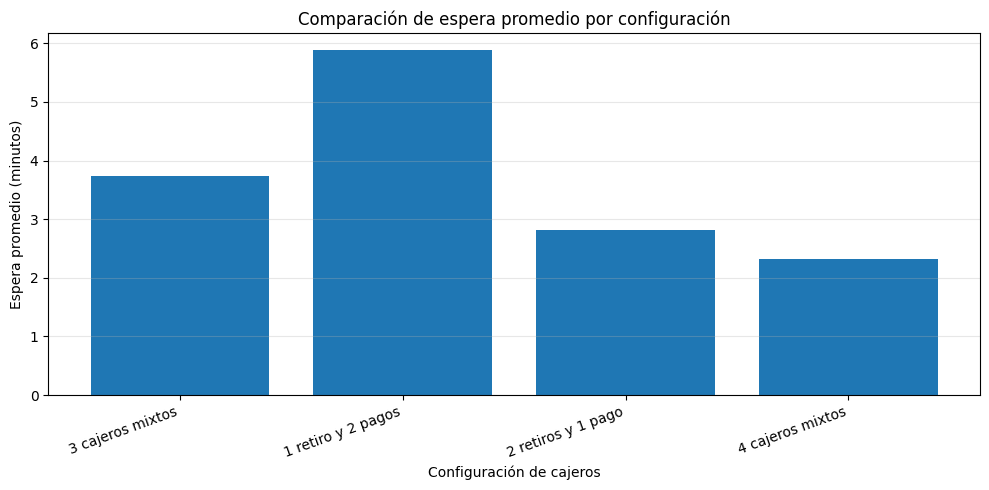

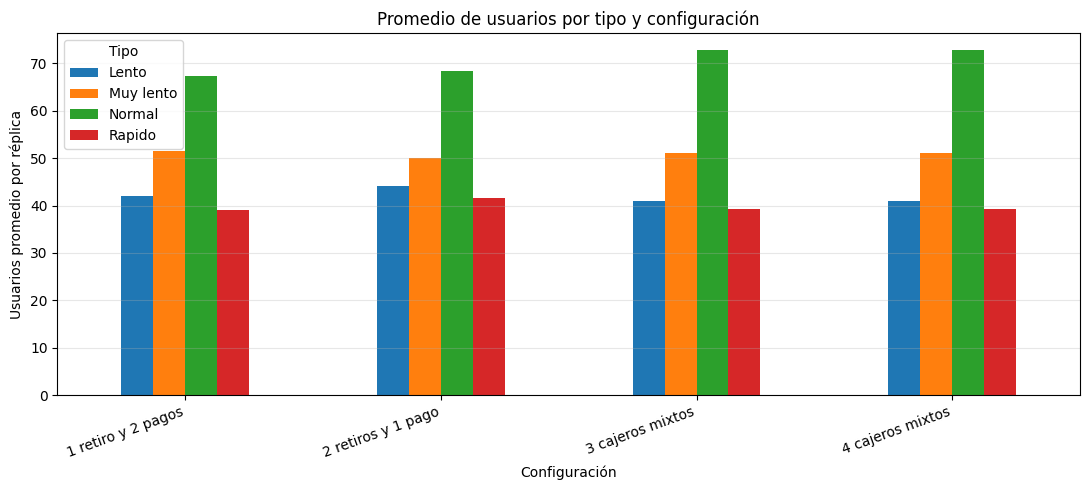


ANÁLISIS COMPLETADO.


In [ ]:

# BLOQUE 6: ANÁLISIS POR CAJERO Y TIPO DE USUARIO


# Unir los datos de las cuatro configuraciones
todos_escenarios = pd.concat(
    datos_escenarios.values(),
    ignore_index=True
)


# 1. TIEMPO PROMEDIO DE SERVICIO POR CAJERO


servicio_por_cajero = (
    todos_escenarios
    .groupby(["Escenario", "Cajero"])["Servicio"]
    .mean()
    .reset_index()
    .rename(columns={
        "Servicio": "Servicio_promedio_minutos"
    })
)

print("TIEMPO PROMEDIO DE SERVICIO POR CAJERO")
display(servicio_por_cajero.round(3))


# 2. PROMEDIO DE USUARIOS POR TIPO


conteo_por_replica = (
    todos_escenarios
    .groupby(["Escenario", "Replica", "Tipo"])
    .size()
    .reset_index(name="Cantidad")
)

promedio_por_tipo = (
    conteo_por_replica
    .groupby(["Escenario", "Tipo"])["Cantidad"]
    .mean()
    .reset_index()
    .rename(columns={
        "Cantidad": "Promedio_usuarios_por_replica"
    })
)

print("\nPROMEDIO DE USUARIOS POR TIPO Y CONFIGURACIÓN")
display(promedio_por_tipo.round(2))



# 3. TOTAL DE USUARIOS POR TIPO
# EN CADA RÉPLICA


tabla_totales = (
    todos_escenarios
    .groupby(["Escenario", "Replica", "Tipo"])
    .size()
    .reset_index(name="Total_usuarios")
)

print("\nTOTALES DE USUARIOS POR TIPO Y RÉPLICA")
display(tabla_totales.head(20))


# 4. CONFIGURACIÓN CON MENOR CANTIDAD
# PROMEDIO DE CADA TIPO DE USUARIO


menores_cantidades = (
    promedio_por_tipo
    .loc[
        promedio_por_tipo.groupby("Tipo")[
            "Promedio_usuarios_por_replica"
        ].idxmin()
    ]
    .reset_index(drop=True)
)

print("\nCONFIGURACIÓN CON MENOR CANTIDAD PROMEDIO POR TIPO")
display(menores_cantidades.round(2))



# 5. GRÁFICA DE ESPERA PROMEDIO


plt.figure(figsize=(10, 5))

plt.bar(
    comparacion_escenarios["Configuracion"],
    comparacion_escenarios["Espera_promedio"]
)

plt.title("Comparación de espera promedio por configuración")
plt.xlabel("Configuración de cajeros")
plt.ylabel("Espera promedio (minutos)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



# 6. GRÁFICA DE USUARIOS POR TIPO


tabla_grafica = promedio_por_tipo.pivot(
    index="Escenario",
    columns="Tipo",
    values="Promedio_usuarios_por_replica"
)

tabla_grafica.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Promedio de usuarios por tipo y configuración")
plt.xlabel("Configuración")
plt.ylabel("Usuarios promedio por réplica")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nANÁLISIS COMPLETADO.")

In [ ]:

# BLOQUE 7: INTERVALOS DE CONFIANZA POR ESCENARIO


from scipy import stats
import numpy as np
import pandas as pd

# Calcular los indicadores de cada una de las 10 réplicas
# para cada una de las cuatro configuraciones.
resumen_replicas = (
    todos_escenarios
    .groupby(["Escenario", "Replica"])
    .agg(
        Usuarios=("Tipo", "size"),
        Espera_promedio=("Espera", "mean"),
        Servicio_promedio=("Servicio", "mean"),
        Tiempo_sistema_promedio=("Tiempo_sistema", "mean")
    )
    .reset_index()
)

indicadores = [
    "Usuarios",
    "Espera_promedio",
    "Servicio_promedio",
    "Tiempo_sistema_promedio"
]

filas_intervalos = []

for escenario, grupo in resumen_replicas.groupby("Escenario"):
    for indicador in indicadores:
        datos = grupo[indicador].dropna()
        n = len(datos)
        media = datos.mean()
        desviacion = datos.std(ddof=1)

        if n >= 2:
            margen = stats.t.ppf(0.975, n - 1) * desviacion / np.sqrt(n)
            inferior = media - margen
            superior = media + margen
        else:
            inferior = np.nan
            superior = np.nan

        filas_intervalos.append({
            "Escenario": escenario,
            "Indicador": indicador,
            "Media": media,
            "Desviacion_estandar": desviacion,
            "IC_inferior_95": inferior,
            "IC_superior_95": superior
        })

tabla_intervalos = pd.DataFrame(filas_intervalos)

print("INTERVALOS DE CONFIANZA DEL 95 % POR CONFIGURACIÓN")
display(tabla_intervalos.round(3))

print("\nCANTIDAD DE RESULTADOS:")
print("Escenarios:", resumen_replicas["Escenario"].nunique())
print("Réplicas por escenario:",
      resumen_replicas.groupby("Escenario")["Replica"].nunique().to_dict())
print("Filas de intervalos:", len(tabla_intervalos))


INTERVALOS DE CONFIANZA DEL 95 % POR CONFIGURACIÓN


,Escenario,Indicador,Media,Desviacion_estandar,IC_inferior_95,IC_superior_95
0,1 retiro y 2 pagos,Usuarios,200.000,16.248,188.377,211.623
1,1 retiro y 2 pagos,Espera_promedio,5.886,4.494,2.671,9.100
2,1 retiro y 2 pagos,Servicio_promedio,3.203,0.366,2.941,3.464
3,1 retiro y 2 pagos,Tiempo_sistema_promedio,9.088,4.775,5.673,12.504
4,2 retiros y 1 pago,Usuarios,204.100,23.459,187.318,220.882
5,2 retiros y 1 pago,Espera_promedio,2.817,0.932,2.150,3.484
6,2 retiros y 1 pago,Servicio_promedio,3.153,0.269,2.960,3.345
7,2 retiros y 1 pago,Tiempo_sistema_promedio,5.970,1.092,5.188,6.751
8,3 cajeros mixtos,Usuarios,204.000,25.403,185.827,222.173
9,3 cajeros mixtos,Espera_promedio,3.733,2.071,2.251,5.214



CANTIDAD DE RESULTADOS:
Escenarios: 4
Réplicas por escenario: {'1 retiro y 2 pagos': 10, '2 retiros y 1 pago': 10, '3 cajeros mixtos': 10, '4 cajeros mixtos': 10}
Filas de intervalos: 16


In [ ]:

# EXPORTACIÓN DE RESULTADOS A EXCEL


nombre_archivo = "Resultados_Actividad_3_Problema_Bancario.xlsx"

with pd.ExcelWriter(nombre_archivo) as writer:
    comparacion_escenarios.to_excel(
        writer, sheet_name="Comparacion_Escenarios", index=False
    )
    tabla_intervalos.to_excel(
        writer, sheet_name="Intervalos_Confianza", index=False
    )
    resumen_replicas.to_excel(
        writer, sheet_name="Resumen_Replicas", index=False
    )

print("Archivo Excel generado correctamente:", nombre_archivo)

# En Google Colab se descargará automáticamente.
try:
    from google.colab import files
    files.download(nombre_archivo)
except ImportError:
    print("Fuera de Google Colab: el archivo quedó guardado en el directorio de trabajo.")


Archivo Excel generado correctamente: Resultados_Actividad_3_Problema_Bancario.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ANALISIS COMPLEMENTARIO - PUNTOS 1, 2 Y 3


# Revisar las columnas disponibles
print("Columnas disponibles:")
print(todos_escenarios.columns.tolist())

# Revisar los primeros registros
display(todos_escenarios.head())

Columnas disponibles:
['Cajero', 'Operacion', 'Tipo', 'Llegada', 'Inicio', 'Servicio', 'Espera', 'Final', 'Tiempo_sistema', 'Replica', 'Escenario']


,Cajero,Operacion,Tipo,Llegada,Inicio,Servicio,Espera,Final,Tiempo_sistema,Replica,Escenario
0,1,Retiro,Rapido,0.584135,0.584135,0.167011,0.000000,0.751146,0.167011,1,3 cajeros mixtos
1,3,Retiro,Muy lento,6.703209,6.703209,3.546515,0.000000,10.249724,3.546515,1,3 cajeros mixtos
2,2,Retiro,Muy lento,8.120230,8.120230,1.975888,0.000000,10.096118,1.975888,1,3 cajeros mixtos
3,1,Retiro,Normal,9.430885,9.430885,7.077961,0.000000,16.508845,7.077961,1,3 cajeros mixtos
4,1,Pago,Lento,12.342538,16.508845,5.214306,4.166307,21.723152,9.380614,1,3 cajeros mixtos


In [ ]:
# Cantidad de registros por escenario
print("REGISTROS POR ESCENARIO:")
display(todos_escenarios.groupby("Escenario").size())

REGISTROS POR ESCENARIO:


,0
Escenario,
1 retiro y 2 pagos,2000
2 retiros y 1 pago,2041
3 cajeros mixtos,2040
4 cajeros mixtos,2040


In [ ]:
# PUNTO 1: TIEMPO PROMEDIO DE SERVICIO POR CAJERO

tiempo_cajero = (
    todos_escenarios
    .groupby(["Escenario", "Cajero"])["Servicio"]
    .mean()
    .reset_index()
)

tiempo_cajero["Servicio"] = tiempo_cajero["Servicio"].round(3)

display(tiempo_cajero)

,Escenario,Cajero,Servicio
0,1 retiro y 2 pagos,1,2.339
1,1 retiro y 2 pagos,2,5.415
2,1 retiro y 2 pagos,3,5.227
3,2 retiros y 1 pago,1,2.442
4,2 retiros y 1 pago,2,2.311
5,2 retiros y 1 pago,3,5.035
6,3 cajeros mixtos,1,3.312
7,3 cajeros mixtos,2,3.499
8,3 cajeros mixtos,3,3.045
9,4 cajeros mixtos,1,3.282


In [ ]:
# PUNTO 2: PROMEDIO DE USUARIOS POR TIPO Y ESCENARIO

usuarios_tipo = (
    todos_escenarios
    .groupby(["Escenario", "Tipo"])
    .size()
    .reset_index(name="Total_usuarios")
)

display(usuarios_tipo)

,Escenario,Tipo,Total_usuarios
0,1 retiro y 2 pagos,Lento,420
1,1 retiro y 2 pagos,Muy lento,516
2,1 retiro y 2 pagos,Normal,674
3,1 retiro y 2 pagos,Rapido,390
4,2 retiros y 1 pago,Lento,441
5,2 retiros y 1 pago,Muy lento,501
6,2 retiros y 1 pago,Normal,683
7,2 retiros y 1 pago,Rapido,416
8,3 cajeros mixtos,Lento,409
9,3 cajeros mixtos,Muy lento,511


In [ ]:
# PUNTO 2: PROMEDIO DE USUARIOS POR TIPO EN CADA ESCENARIO

promedio_usuarios = (
    todos_escenarios
    .groupby(["Escenario", "Replica", "Tipo"])
    .size()
    .reset_index(name="Cantidad")
    .groupby(["Escenario", "Tipo"])["Cantidad"]
    .mean()
    .reset_index(name="Promedio_usuarios")
)

promedio_usuarios["Promedio_usuarios"] = (
    promedio_usuarios["Promedio_usuarios"].round(2)
)

display(promedio_usuarios)

,Escenario,Tipo,Promedio_usuarios
0,1 retiro y 2 pagos,Lento,42.0
1,1 retiro y 2 pagos,Muy lento,51.6
2,1 retiro y 2 pagos,Normal,67.4
3,1 retiro y 2 pagos,Rapido,39.0
4,2 retiros y 1 pago,Lento,44.1
5,2 retiros y 1 pago,Muy lento,50.1
6,2 retiros y 1 pago,Normal,68.3
7,2 retiros y 1 pago,Rapido,41.6
8,3 cajeros mixtos,Lento,40.9
9,3 cajeros mixtos,Muy lento,51.1


In [ ]:
# PUNTO 3: TOTAL DE USUARIOS POR TIPO EN CADA RÉPLICA

totales_replica = (
    todos_escenarios
    .groupby(["Escenario", "Replica", "Tipo"])
    .size()
    .reset_index(name="Total_usuarios")
)

display(totales_replica)

,Escenario,Replica,Tipo,Total_usuarios
0,1 retiro y 2 pagos,1,Lento,42
1,1 retiro y 2 pagos,1,Muy lento,47
2,1 retiro y 2 pagos,1,Normal,61
3,1 retiro y 2 pagos,1,Rapido,34
4,1 retiro y 2 pagos,2,Lento,46
...,...,...,...,...
155,4 cajeros mixtos,9,Rapido,36
156,4 cajeros mixtos,10,Lento,53
157,4 cajeros mixtos,10,Muy lento,51
158,4 cajeros mixtos,10,Normal,70


In [ ]:
# PUNTO 3: COMPARACIÓN DE USUARIOS POR TIPO Y ESCENARIO

comparacion_tipos = (
    totales_replica
    .groupby(["Escenario", "Tipo"])["Total_usuarios"]
    .mean()
    .reset_index(name="Promedio_10_replicas")
)

comparacion_tipos["Promedio_10_replicas"] = (
    comparacion_tipos["Promedio_10_replicas"].round(2)
)

display(comparacion_tipos)

# Escenario con menor promedio para cada tipo de usuario
menor_por_tipo = (
    comparacion_tipos
    .loc[comparacion_tipos.groupby("Tipo")["Promedio_10_replicas"].idxmin()]
    .reset_index(drop=True)
)

print("ESCENARIO CON MENOR PROMEDIO POR TIPO:")
display(menor_por_tipo)

,Escenario,Tipo,Promedio_10_replicas
0,1 retiro y 2 pagos,Lento,42.0
1,1 retiro y 2 pagos,Muy lento,51.6
2,1 retiro y 2 pagos,Normal,67.4
3,1 retiro y 2 pagos,Rapido,39.0
4,2 retiros y 1 pago,Lento,44.1
5,2 retiros y 1 pago,Muy lento,50.1
6,2 retiros y 1 pago,Normal,68.3
7,2 retiros y 1 pago,Rapido,41.6
8,3 cajeros mixtos,Lento,40.9
9,3 cajeros mixtos,Muy lento,51.1


ESCENARIO CON MENOR PROMEDIO POR TIPO:


,Escenario,Tipo,Promedio_10_replicas
0,3 cajeros mixtos,Lento,40.9
1,2 retiros y 1 pago,Muy lento,50.1
2,1 retiro y 2 pagos,Normal,67.4
3,1 retiro y 2 pagos,Rapido,39.0


In [ ]:
tabla_replica = totales_replica.pivot_table(
    index=["Escenario", "Replica"],
    columns="Tipo",
    values="Total_usuarios"
).reset_index()

display(tabla_replica)

Tipo,Escenario,Replica,Lento,Muy lento,Normal,Rapido
0,1 retiro y 2 pagos,1,42.0,47.0,61.0,34.0
1,1 retiro y 2 pagos,2,46.0,61.0,79.0,38.0
2,1 retiro y 2 pagos,3,39.0,57.0,63.0,27.0
3,1 retiro y 2 pagos,4,44.0,48.0,72.0,49.0
4,1 retiro y 2 pagos,5,48.0,39.0,61.0,39.0
5,1 retiro y 2 pagos,6,40.0,51.0,62.0,35.0
6,1 retiro y 2 pagos,7,51.0,58.0,72.0,47.0
7,1 retiro y 2 pagos,8,37.0,59.0,65.0,39.0
8,1 retiro y 2 pagos,9,28.0,57.0,71.0,43.0
9,1 retiro y 2 pagos,10,45.0,39.0,68.0,39.0


In [ ]:


# PUNTO 4. ANALISIS DEFINITIVO DEL TIEMPO DE ESPERA


import numpy as np
import pandas as pd
from scipy.stats import t

# 1. Calcular el tiempo promedio de espera de cada réplica
espera_replicas = (
    todos_escenarios
    .groupby(["Escenario", "Replica"])["Espera"]
    .mean()
    .reset_index(name="Espera_promedio")
)

# 2. Calcular media y desviación estándar entre las 10 réplicas
resumen_espera = (
    espera_replicas
    .groupby("Escenario")["Espera_promedio"]
    .agg(Media_espera="mean", Desviacion_estandar="std", N="count")
    .reset_index()
)

# 3. Calcular intervalos de confianza del 95 %
resumen_espera["Error_estandar"] = (
    resumen_espera["Desviacion_estandar"] /
    np.sqrt(resumen_espera["N"])
)

resumen_espera["Margen_error"] = (
    t.ppf(0.975, resumen_espera["N"] - 1) *
    resumen_espera["Error_estandar"]
)

resumen_espera["IC_inferior"] = (
    resumen_espera["Media_espera"] -
    resumen_espera["Margen_error"]
)

resumen_espera["IC_superior"] = (
    resumen_espera["Media_espera"] +
    resumen_espera["Margen_error"]
)

# 4. Presentar resultados
columnas = [
    "Escenario",
    "Media_espera",
    "Desviacion_estandar",
    "IC_inferior",
    "IC_superior"
]

print("TIEMPO PROMEDIO DE ESPERA POR CONFIGURACIÓN")
display(resumen_espera[columnas].round(3))

# 5. Identificar la configuración con menor espera
mejor_configuracion = resumen_espera.loc[
    resumen_espera["Media_espera"].idxmin()
]

print("\nCONFIGURACIÓN CON MENOR TIEMPO PROMEDIO DE ESPERA:")
print(mejor_configuracion["Escenario"])
print(
    f"Tiempo promedio: "
    f"{mejor_configuracion['Media_espera']:.3f} minutos"
)

# 6. Tabla para comparar los promedios por réplica
display(
    espera_replicas.pivot(
        index="Replica",
        columns="Escenario",
        values="Espera_promedio"
    ).round(3)
)


TIEMPO PROMEDIO DE ESPERA POR CONFIGURACIÓN


,Escenario,Media_espera,Desviacion_estandar,IC_inferior,IC_superior
0,1 retiro y 2 pagos,5.886,4.494,2.671,9.100
1,2 retiros y 1 pago,2.817,0.932,2.150,3.484
2,3 cajeros mixtos,3.733,2.071,2.251,5.214
3,4 cajeros mixtos,2.323,1.231,1.442,3.204



CONFIGURACIÓN CON MENOR TIEMPO PROMEDIO DE ESPERA:
4 cajeros mixtos
Tiempo promedio: 2.323 minutos


Escenario,1 retiro y 2 pagos,2 retiros y 1 pago,3 cajeros mixtos,4 cajeros mixtos
Replica,,,,
1,3.497,1.351,2.568,2.011
2,4.892,2.507,5.746,2.794
3,2.314,2.168,1.500,0.618
4,4.232,1.928,2.282,1.217
5,16.100,3.536,7.819,4.737
6,5.829,3.499,2.362,1.841
7,4.489,2.867,3.779,2.089
8,11.728,3.569,2.465,2.171
9,2.118,2.325,2.821,1.770


In [ ]:
# INTERVALOS DE CONFIANZA DEL 95% PARA EL TIEMPO DE ESPERA

from scipy.stats import t
import numpy as np

intervalos_espera = (
    espera_replicas
    .groupby("Escenario")["Espera_promedio"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

intervalos_espera["Error_estandar"] = (
    intervalos_espera["std"] /
    np.sqrt(intervalos_espera["count"])
)

intervalos_espera["Margen_error"] = (
    t.ppf(0.975, intervalos_espera["count"] - 1) *
    intervalos_espera["Error_estandar"]
)

intervalos_espera["IC_inferior"] = (
    intervalos_espera["mean"] -
    intervalos_espera["Margen_error"]
)

intervalos_espera["IC_superior"] = (
    intervalos_espera["mean"] +
    intervalos_espera["Margen_error"]
)

display(intervalos_espera.round(3))

,Escenario,mean,std,count,Error_estandar,Margen_error,IC_inferior,IC_superior
0,1 retiro y 2 pagos,5.886,4.494,10,1.421,3.215,2.671,9.100
1,2 retiros y 1 pago,2.817,0.932,10,0.295,0.667,2.150,3.484
2,3 cajeros mixtos,3.733,2.071,10,0.655,1.481,2.251,5.214
3,4 cajeros mixtos,2.323,1.231,10,0.389,0.881,1.442,3.204


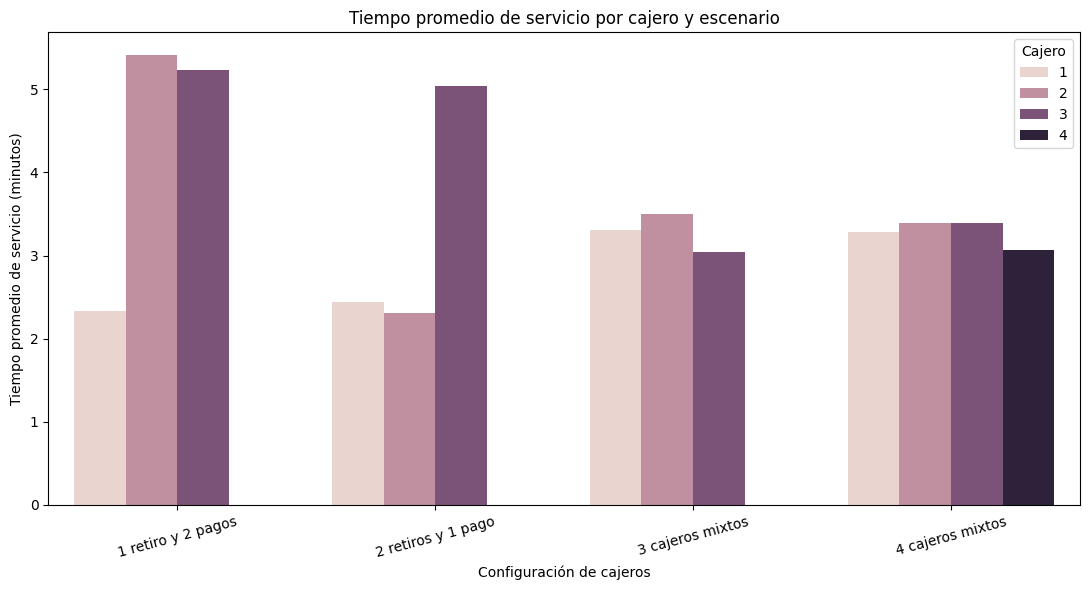

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.barplot(
    data=tiempo_cajero,
    x="Escenario",
    y="Servicio",
    hue="Cajero"
)

plt.title("Tiempo promedio de servicio por cajero y escenario")
plt.xlabel("Configuración de cajeros")
plt.ylabel("Tiempo promedio de servicio (minutos)")
plt.xticks(rotation=15)
plt.legend(title="Cajero")
plt.tight_layout()
plt.show()

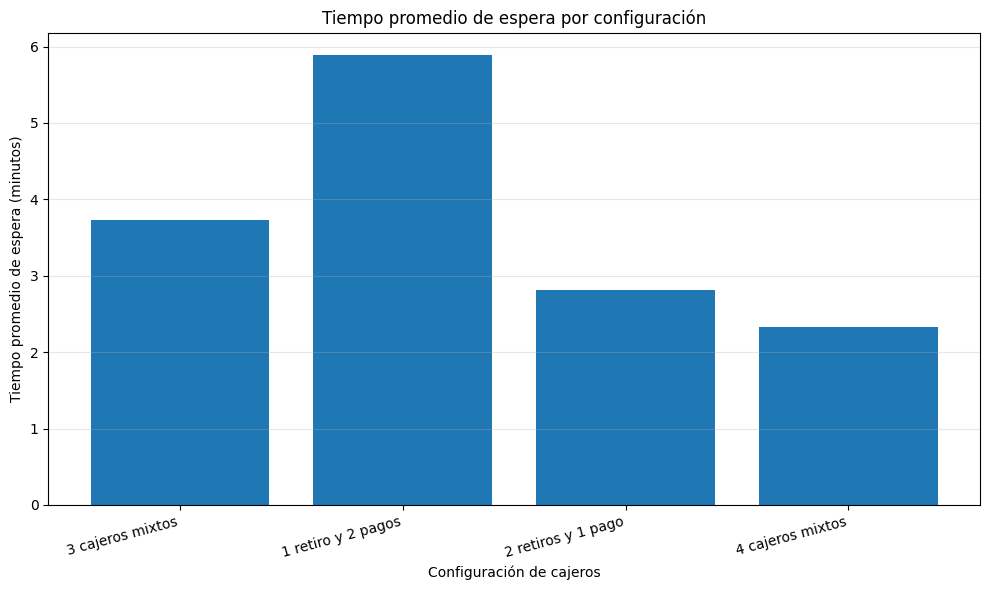

In [ ]:
# Gráfica 2: comparación del tiempo promedio de espera

plt.figure(figsize=(10, 6))

plt.bar(
    comparacion_escenarios["Configuracion"],
    comparacion_escenarios["Espera_promedio"]
)

plt.title("Tiempo promedio de espera por configuración")
plt.xlabel("Configuración de cajeros")
plt.ylabel("Tiempo promedio de espera (minutos)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
